# Coverage & timeline base

Shared base for coverage/timeline figures. Loads two gap-summary + visit-summary CSV pairs - neural (`data_coverage.py` output) and video - into separate dataframes throughout, so both can be plotted (eventually overlaid on the same timeline). Shows:

1. Per-patient data coverage (`pct_coverage` histogram), neural vs. video
2. Good-data intervals (the complement of the gap intervals within each admission's recorded span), for each source
3. Per-patient recording timeline (whole time course, gaps marked), neural and video overlaid

All functions here take the relevant column names as arguments, so the same code can be pointed at a differently-columned CSV without editing the functions themselves.

**Caveat carried over from `coverage_visualizations.ipynb`:** the good-data intervals below only subtract each source's own `gap_summary.csv` gaps, not `imputed_gaps.csv`'s clock-corruption bridges.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import os

from plotting_utils import style_hist_axes, stepfilled_hist, stepfilled_bars

NEURAL_GAP_SUMMARY_CSV = '../phi-data/detailedv1/gaps.csv'
NEURAL_VISIT_SUMMARY_CSV = '../phi-data/detailedv1/visit_summary_corrected.csv'

VIDEO_GAP_SUMMARY_CSV = '../phi-data/video_gaps.csv'
VIDEO_VISIT_SUMMARY_CSV = '../phi-data/video_visit_summary.csv'

OUT_FOLDER = r'D:\Work\Publication\EMU247 2026\availability fig'

def load_coverage(
    gap_summary_csv, visit_summary_csv, label,
    emu_col='emu_id',
    gap_start_col='gap_start_utc', gap_end_col='gap_end_utc',
    visit_start_col='recording_start_utc', visit_end_col='recording_end_utc',
):
    gaps_df = pd.read_csv(gap_summary_csv)
    visits_df = pd.read_csv(visit_summary_csv)
    # Both CSVs store UTC timestamps, but not consistently formatted - some rows have fractional
    # seconds and/or an explicit "+00:00" offset, others don't (Python's datetime.isoformat()
    # omits both when they're zero/absent), so a single fixed format doesn't match every row.
    # format='ISO8601' parses each value against whichever valid ISO8601 variant it actually is,
    # and utc=True still forces the result to tz-aware UTC regardless.
    for col in (gap_start_col, gap_end_col):
        gaps_df[col] = pd.to_datetime(gaps_df[col], format='ISO8601', utc=True)
    for col in (visit_start_col, visit_end_col):
        visits_df[col] = pd.to_datetime(visits_df[col], format='ISO8601', utc=True)
    print(f'{label}: {len(gaps_df)} gaps across {gaps_df[emu_col].nunique()} patient(s)')
    print(f'{label}: {len(visits_df)} admission(s) across {visits_df[emu_col].nunique()} patient(s)')
    return gaps_df, visits_df


gaps_neural, visits_neural = load_coverage(NEURAL_GAP_SUMMARY_CSV, NEURAL_VISIT_SUMMARY_CSV, 'neural')
gaps_video, visits_video = load_coverage(VIDEO_GAP_SUMMARY_CSV, VIDEO_VISIT_SUMMARY_CSV, 'video')

neural: 785 gaps across 29 patient(s)
neural: 29 admission(s) across 29 patient(s)
video: 66 gaps across 16 patient(s)
video: 26 admission(s) across 26 patient(s)


In [2]:
# "AV Sync style" overlapping-histogram look (see "AV Sync style example.png"): filled step
# histograms at partial opacity so the overlap region blends, minimal chrome (no top/right
# spine, thick left/bottom spines), large bold labels - style_hist_axes/stepfilled_hist imported
# above, from plotting_utils.py. Colors are placeholders - a light/dark colorblind-safe pair -
# swap NEURAL_COLOR/VIDEO_COLOR for your own and every plot below follows.
NEURAL_COLOR = '#2a78d6'
NEURAL_DARK = '#0251b0'
VIDEO_COLOR = '#eb6834'
VIDEO_DARK = '#b53300'

## Neural vs. video recording start/end time gaps

For each patient with both a neural and a video admission, how far apart the two systems'
recording start times are, and how far apart their end ("checkout") times are.

## Per-patient data coverage

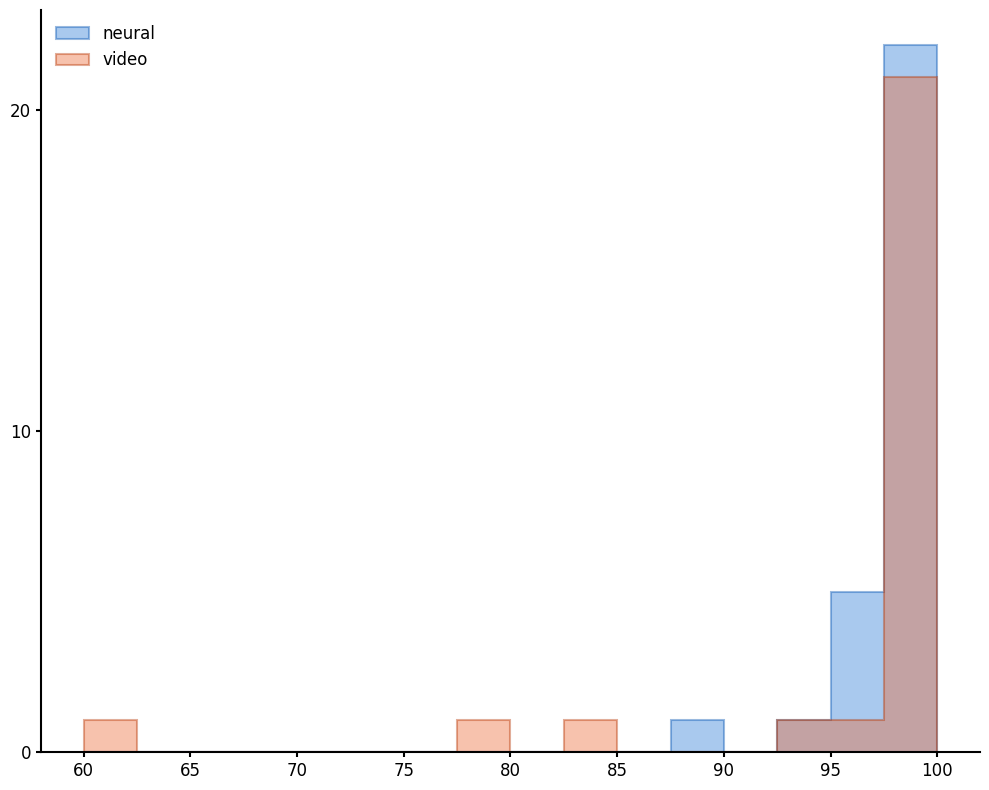

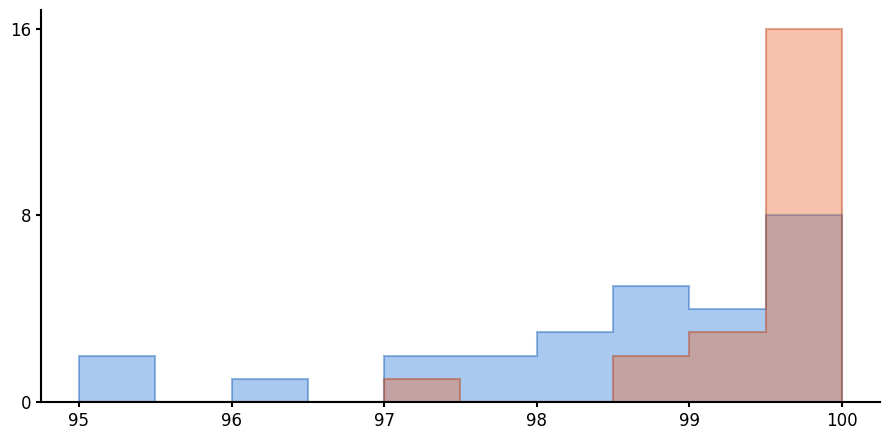

In [3]:
def plot_coverage_hist(visits_df, coverage_col='pct_coverage', ax=None, label=None, color='tab:blue', edgecolor=None, bins=None):
    """Histogram of per-admission data coverage (%), drawn in the AV Sync filled-step style so
    multiple sources overlaid on one ax (e.g. neural and video) blend where they overlap."""
    ax = ax or plt.gca()
    stepfilled_hist(ax, visits_df[coverage_col], color=color, edgecolor=edgecolor, bins=bins, label=label)
    #ax.set_xlabel('Data Coverage (%)')
    #ax.set_ylabel('Patient Count')
    style_hist_axes(ax)


fig, ax = plt.subplots(figsize=(10,8))
big_bins = np.linspace(60, 100, num=17, endpoint=True)
plot_coverage_hist(visits_neural, bins=big_bins, ax=ax, label='neural', color=NEURAL_COLOR, edgecolor=NEURAL_DARK)
plot_coverage_hist(visits_video, bins=big_bins, ax=ax, label='video', color=VIDEO_COLOR, edgecolor=VIDEO_DARK)
ax.legend(frameon=False, fontsize=12)
ax.set_yticks([0,10,20])
plt.tight_layout()
plt.savefig(os.path.join(OUT_FOLDER, 'patient_coverage_wide.png'), dpi=300)
# ax.legend(frameon=False, fontsize=12)

fig, ax = plt.subplots(figsize=(9, 4.5))
zoom_bins = np.linspace(95, 100, 11, endpoint=True)
ax.set_yticks([0,8,16])
plot_coverage_hist(visits_neural, bins=zoom_bins, ax=ax, label='neural', color=NEURAL_COLOR, edgecolor=NEURAL_DARK)
plot_coverage_hist(visits_video, bins=zoom_bins, ax=ax, label='video', color=VIDEO_COLOR, edgecolor=VIDEO_DARK)
plt.tight_layout()
plt.savefig(os.path.join(OUT_FOLDER, 'patient_coverage_zoom.png'), dpi=300)

## Good-data intervals

For each admission, take its `[visit_start_col, visit_end_col]` span from the visit-summary table and subtract every gap interval (sorted by start) from the gap table, to get the complementary continuous "good data" spans. Computed separately per source.

In [4]:
def good_intervals_for_admission(recording_start, recording_end, admission_gaps, gap_start_col, gap_end_col):
    """Complement of admission_gaps (sorted by start) within [recording_start, recording_end]."""
    admission_gaps = admission_gaps.sort_values(gap_start_col)

    intervals = []
    cursor = recording_start
    for _, gap in admission_gaps.iterrows():
        if gap[gap_start_col] > cursor:
            intervals.append((cursor, gap[gap_start_col]))
        cursor = max(cursor, gap[gap_end_col])
    if recording_end > cursor:
        intervals.append((cursor, recording_end))
    return intervals


def build_good_intervals(
    gaps_df, visits_df,
    patient_col='emu_id',
    visit_start_col='recording_start_utc', visit_end_col='recording_end_utc',
    gap_start_col='gap_start_utc', gap_end_col='gap_end_utc',
):
    """
    One row per continuous good-data interval, across every admission in visits_df. Output
    columns are always named patient_col/admission_col/emu_col (passed through) plus the
    fixed 'good_start_utc'/'good_end_utc'/'duration_hours', regardless of the input gap/visit
    column names, so downstream plotting code doesn't need to know the source CSV's schema.
    """
    rows = []
    for _, visit in visits_df.iterrows():
        admission_gaps = gaps_df[
            (gaps_df[patient_col] == visit[patient_col])
        ]
        for good_start, good_end in good_intervals_for_admission(
            visit[visit_start_col], visit[visit_end_col], admission_gaps, gap_start_col, gap_end_col
        ):
            rows.append({
                patient_col: visit[patient_col],
                'good_start_utc': good_start,
                'good_end_utc': good_end,
                'duration_hours': (good_end - good_start).total_seconds() / 3600,
            })
    return pd.DataFrame(rows)


good_intervals_neural = build_good_intervals(gaps_neural, visits_neural)
good_intervals_video = build_good_intervals(gaps_video, visits_video)
print(f'{len(good_intervals_neural)} neural, {len(good_intervals_video)} video good-data interval(s)')
good_intervals_neural.head()

805 neural, 92 video good-data interval(s)


,emu_id,good_start_utc,good_end_utc,duration_hours
0,YFA,2024-04-23 01:03:01.899000+00:00,2024-04-23 14:55:54.375000+00:00,13.881243
1,YFA,2024-04-23 15:03:47.365000+00:00,2024-04-23 17:12:38.354600+00:00,2.147497
2,YFA,2024-04-23 17:14:33.364000+00:00,2024-04-23 17:35:07.610000+00:00,0.342846
3,YFA,2024-04-23 17:48:41.528000+00:00,2024-04-23 18:04:17.866466+00:00,0.260094
4,YFA,2024-04-23 18:25:27.361800+00:00,2024-04-23 22:13:15.206000+00:00,3.796623


## Data availability / missing data over time since visit start

Two panels sharing an x-axis (hours elapsed since each patient's own visit start, pooled across
patients): available hours per time bin on top, missing (gap) hours per time bin below - both in
the AV Sync filled-step style, neural and video overlaid.

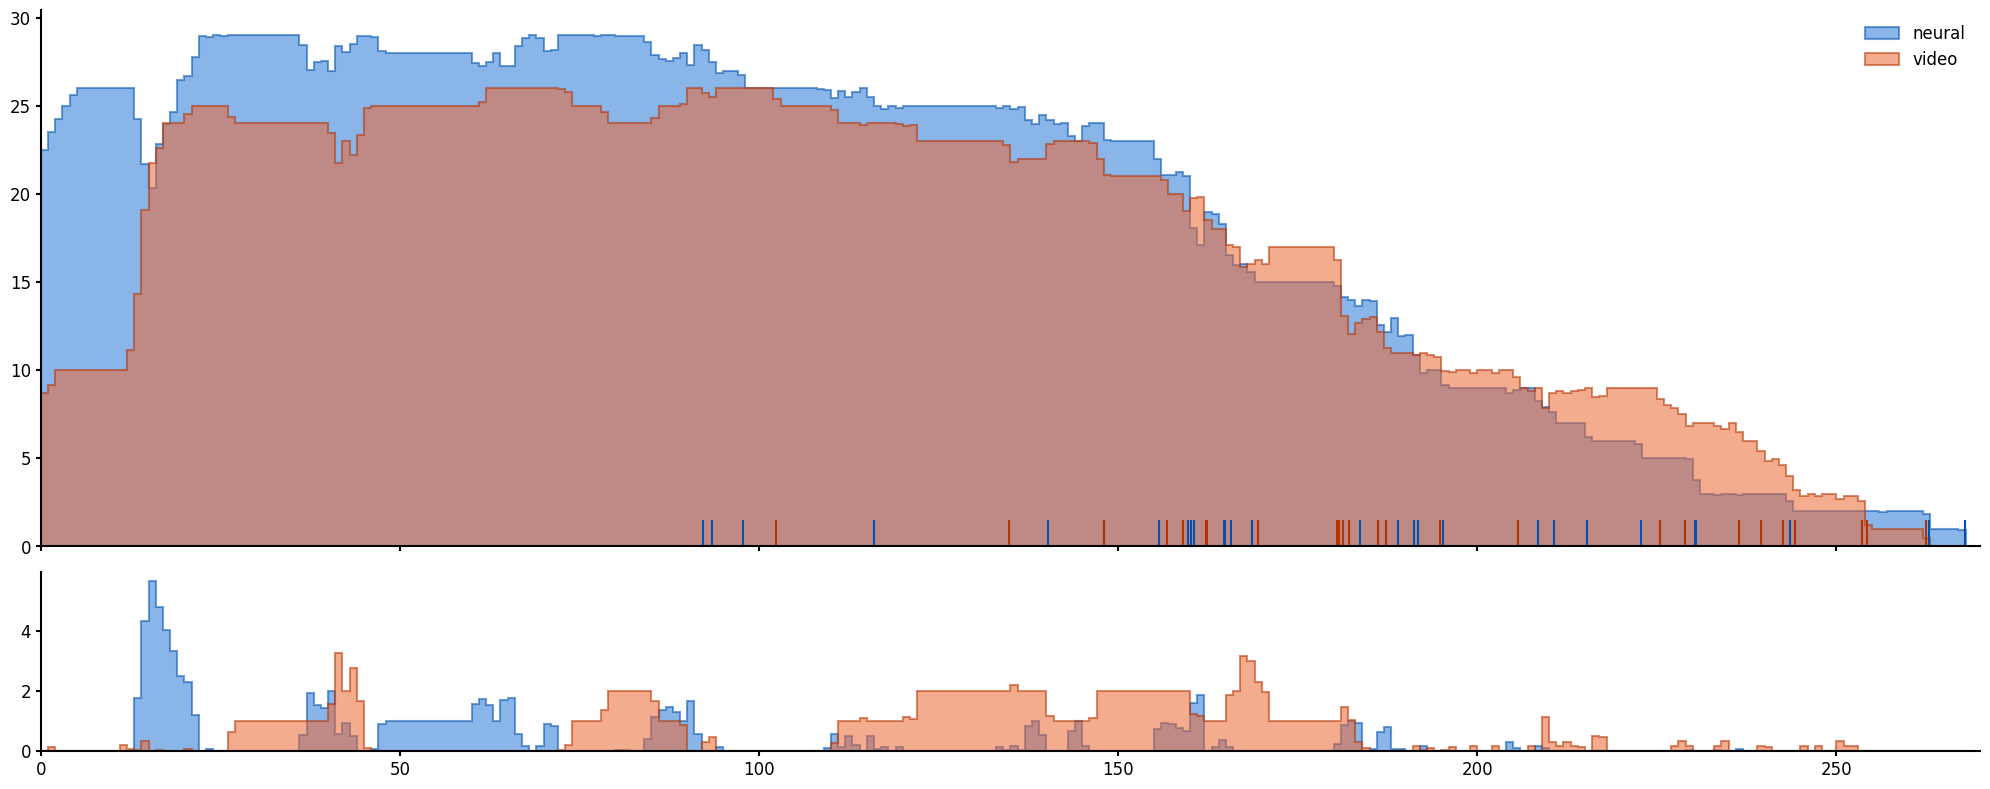

In [5]:
TIME_BIN_HOURS = 1


def shared_visit_starts(visits_dfs, id_col='emu_id', start_col='recording_start_utc'):
    """Per-patient earliest recording start across multiple visits tables (neural and video) -
    the actual start of the "visit" once both systems are accounted for, since the two
    recordings don't start at the same time. Everything measured "since visit start" below is
    relative to this shared start, not either source's own."""
    return pd.concat([df[[id_col, start_col]] for df in visits_dfs]).groupby(id_col)[start_col].min()


def with_elapsed_hours(df, start_col, end_col, visit_start_by_patient, id_col='emu_id'):
    """Add elapsed_start_hours/elapsed_end_hours columns to a copy of df, each row's elapsed
    time measured from ITS OWN patient's shared visit start (visit_start_by_patient - the
    earlier of the neural/video recording starts, from shared_visit_starts)."""
    visit_start = df[id_col].map(visit_start_by_patient)
    out = df.copy()
    out['elapsed_start_hours'] = (df[start_col] - visit_start).dt.total_seconds() / 3600
    out['elapsed_end_hours'] = (df[end_col] - visit_start).dt.total_seconds() / 3600
    return out


def overlap_duration_per_bin(starts, ends, bin_edges):
    """For each bin [bin_edges[i], bin_edges[i+1]), sum the overlap duration of every
    (start, end) interval with that bin - i.e. total interval-hours per elapsed-time bin,
    pooled across whatever intervals are passed in."""
    starts = np.asarray(starts)
    ends = np.asarray(ends)
    totals = np.zeros(len(bin_edges) - 1)
    for i in range(len(bin_edges) - 1):
        b0, b1 = bin_edges[i], bin_edges[i + 1]
        overlap = np.clip(np.minimum(ends, b1) - np.maximum(starts, b0), 0, None)
        totals[i] = overlap.sum()
    return totals


def visit_end_hours(visits_df, visit_start_by_patient, id_col='emu_id', visit_end_col='recording_end_utc'):
    """Each admission's checkout time, in hours elapsed since that patient's shared visit start
    (visit_start_by_patient), not that source's own recording start."""
    visit_start = visits_df[id_col].map(visit_start_by_patient)
    return (visits_df[visit_end_col] - visit_start).dt.total_seconds() / 3600


visit_start_by_patient = shared_visit_starts([visits_neural, visits_video])

good_elapsed_neural = with_elapsed_hours(good_intervals_neural, 'good_start_utc', 'good_end_utc', visit_start_by_patient)
gaps_elapsed_neural = with_elapsed_hours(gaps_neural, 'gap_start_utc', 'gap_end_utc', visit_start_by_patient)
good_elapsed_video = with_elapsed_hours(good_intervals_video, 'good_start_utc', 'good_end_utc', visit_start_by_patient)
gaps_elapsed_video = with_elapsed_hours(gaps_video, 'gap_start_utc', 'gap_end_utc', visit_start_by_patient)

visit_ends_neural = visit_end_hours(visits_neural, visit_start_by_patient)
visit_ends_video = visit_end_hours(visits_video, visit_start_by_patient)

max_elapsed = max(
    good_elapsed_neural['elapsed_end_hours'].max(), good_elapsed_video['elapsed_end_hours'].max(),
)
bin_edges = np.arange(0, max_elapsed + 1*TIME_BIN_HOURS, TIME_BIN_HOURS)

availability_neural = overlap_duration_per_bin(
    good_elapsed_neural['elapsed_start_hours'], good_elapsed_neural['elapsed_end_hours'], bin_edges
)
availability_video = overlap_duration_per_bin(
    good_elapsed_video['elapsed_start_hours'], good_elapsed_video['elapsed_end_hours'], bin_edges
)
missing_neural = overlap_duration_per_bin(
    gaps_elapsed_neural['elapsed_start_hours'], gaps_elapsed_neural['elapsed_end_hours'], bin_edges
)
missing_video = overlap_duration_per_bin(
    gaps_elapsed_video['elapsed_start_hours'], gaps_elapsed_video['elapsed_end_hours'], bin_edges
)

fig, (ax_avail, ax_missing) = plt.subplots(
    2, 1, figsize=(20, 8), sharex=True, gridspec_kw={'height_ratios': [6, 2]}
)

stepfilled_bars(ax_avail, availability_neural, bin_edges, color=NEURAL_COLOR, label='neural', edgecolor=NEURAL_DARK)
stepfilled_bars(ax_avail, availability_video, bin_edges, color=VIDEO_COLOR, label='video', edgecolor=VIDEO_DARK)
#ax_avail.set_ylabel('Available hours')
ax_avail.legend(frameon=False, fontsize=12)
style_hist_axes(ax_avail)
ax_avail.tick_params(labelbottom=False)

stepfilled_bars(ax_missing, missing_neural, bin_edges, color=NEURAL_COLOR, label='neural', edgecolor=NEURAL_DARK)
stepfilled_bars(ax_missing, missing_video, bin_edges, color=VIDEO_COLOR, label='video', edgecolor=VIDEO_DARK)
#ax_missing.set_ylabel('Missing hours')
style_hist_axes(ax_missing)
ax_missing.tick_params(labelbottom=True)

ylims = ax_avail.get_ylim()
rug_ht = (ylims[1] - ylims[0]) * 0.05
rug_y = ylims[0], ylims[0]+rug_ht
ax_avail.vlines(visit_ends_neural, *rug_y, color=NEURAL_DARK, linewidth=1.5)
ax_avail.vlines(visit_ends_video, *rug_y, color=VIDEO_DARK, linewidth=1.5)
# ax_checkout.set_ylabel('Recording\nEnds',  ha='right', va='center', fontsize=10)
#ax_missing.set_xlabel('Time since visit start (hours)')
style_hist_axes(ax_missing)
ax_missing.set_xlim([0, 270])

plt.tight_layout()
plt.savefig(os.path.join(OUT_FOLDER, 'DataAvailability.png'), dpi=300)
plt.show()

## Per-patient recording timeline

One plot per patient, spanning that patient's whole recorded time course. Neural is drawn as a filled blue band (gaps marked in red above it); video is overlaid as a filled orange band (gaps marked in a darker red, slightly higher) on the same axes. A gap shorter than `SHORT_GAP_THRESHOLD_MINUTES` is drawn as a single point at its midpoint; a longer gap also gets a thin line spanning its full duration.

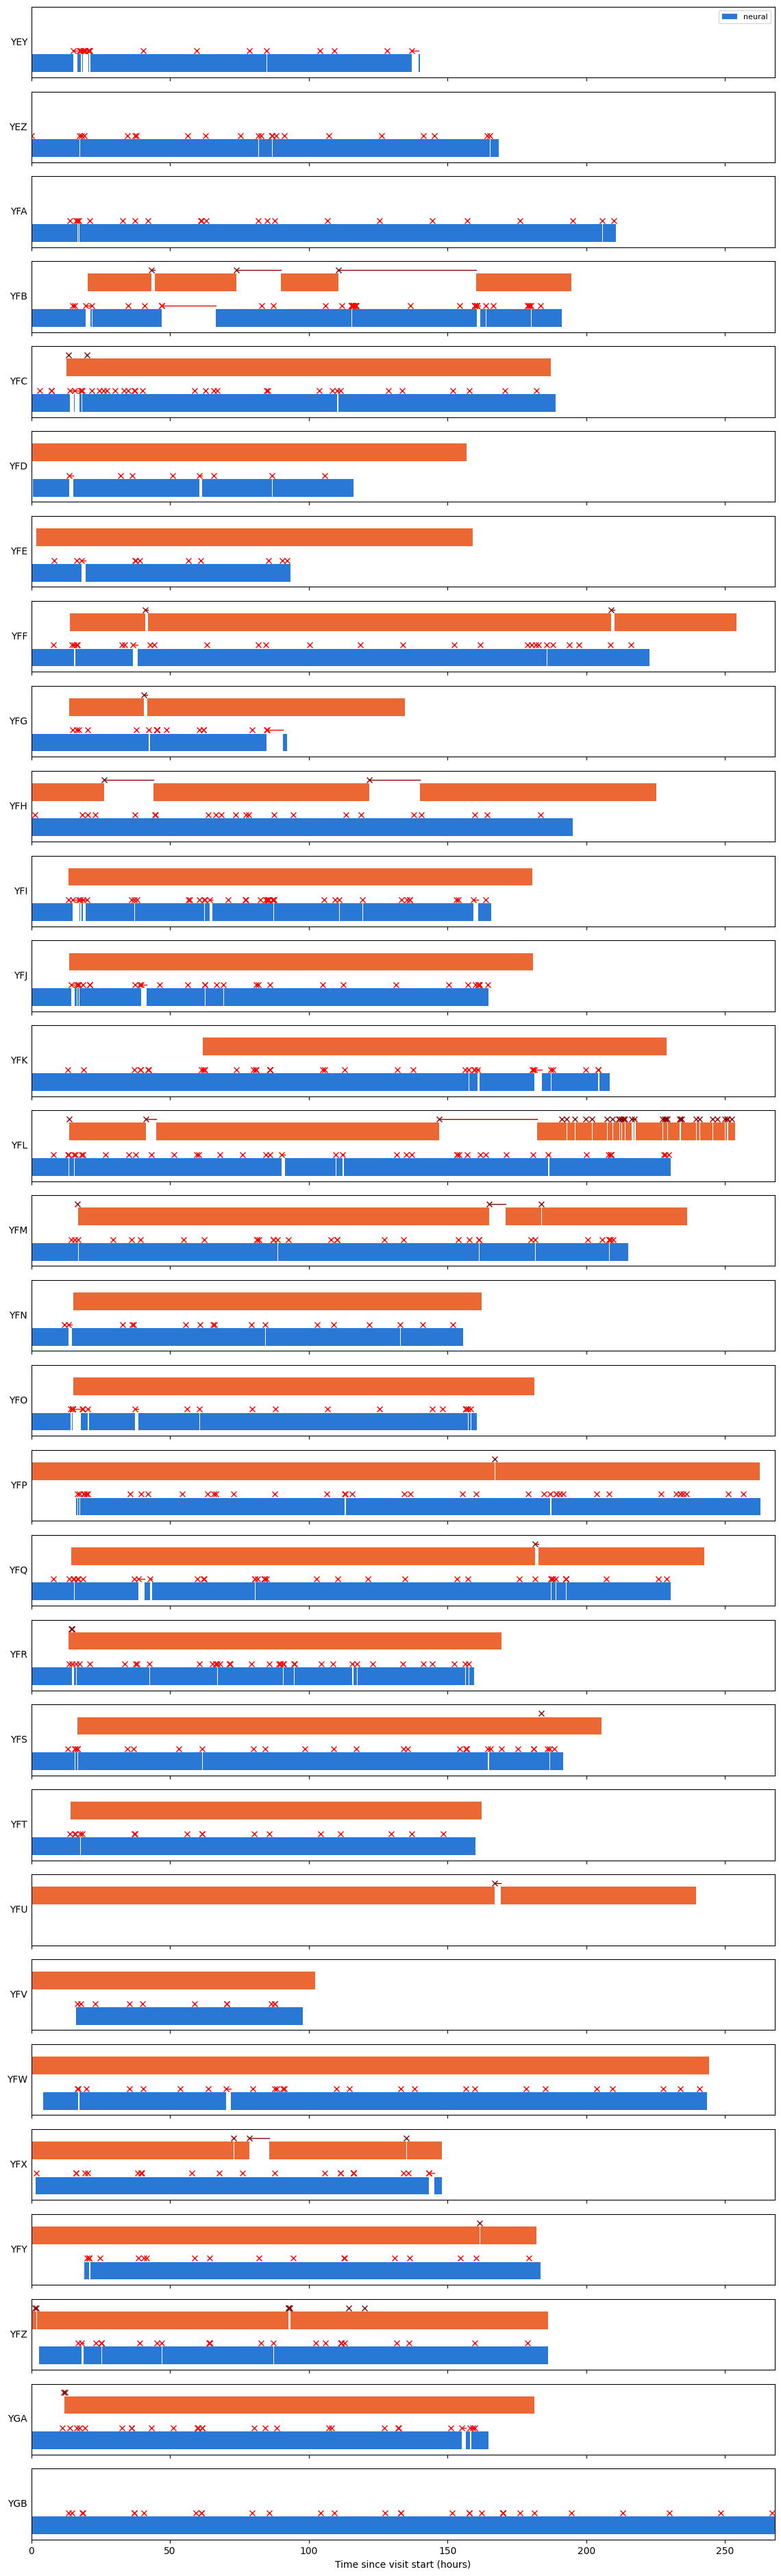

In [6]:
SHORT_GAP_THRESHOLD_MINUTES = 10  # gaps shorter than this show as a single point only


def plot_patient_timeline(
    ax, patient_id, good_df, gap_df, visit_start,
    id_col='emu_id',
    good_start_col='good_start_utc', good_end_col='good_end_utc',
    gap_start_col='gap_start_utc', gap_end_col='gap_end_utc',
    short_gap_threshold_minutes=SHORT_GAP_THRESHOLD_MINUTES,
    good_color='tab:blue', gap_color='red', y_offset=0.0, label=None,
):
    """
    Draw one patient's whole recording time course onto `ax`, x-axis as hours elapsed since
    visit_start - the patient's SHARED visit start (the earlier of the neural/video recording
    starts, from visit_start_by_patient), not this source's own start, so neural and video are
    plotted on a common time origin. Available (good) data is a filled band in good_color, gaps
    are gap_color markers above it. A gap shorter than short_gap_threshold_minutes is a single
    point at its midpoint; a longer gap also gets a thin line spanning its full duration.
    y_offset shifts this source's band up (in the same [0, 1]-per-source vertical scale) so
    multiple sources can be overlaid on one ax without occluding each other.
    """
    patient_good = good_df[good_df[id_col] == patient_id]
    patient_gaps = gap_df[gap_df[id_col] == patient_id]

    def elapsed_hours(timestamp):
        return (timestamp - visit_start).total_seconds() / 3600

    bars = [
        (elapsed_hours(row[good_start_col]), elapsed_hours(row[good_end_col]) - elapsed_hours(row[good_start_col]))
        for _, row in patient_good.iterrows()
    ]
    ax.broken_barh(bars, (y_offset, 1), facecolors=good_color, label=label)

    threshold_hours = short_gap_threshold_minutes / 60
    marker_y = y_offset + 1.2
    for _, gap in patient_gaps.iterrows():
        start, end = elapsed_hours(gap[gap_start_col]), elapsed_hours(gap[gap_end_col])
        if (end - start) >= threshold_hours:
            ax.plot([start, end], [marker_y, marker_y], color=gap_color, linewidth=1)
        ax.plot(start, marker_y, marker='x', color=gap_color, linestyle='None')

    ax.set_yticks([])
    ax.set_ylabel(str(patient_id), rotation=0, ha='right', va='center')


patients = sorted(
    set(good_intervals_neural['emu_id']) | set(gaps_neural['emu_id'])
    | set(good_intervals_video['emu_id']) | set(gaps_video['emu_id'])
)
shared_xlim = (0, max_elapsed)

fig, axes = plt.subplots(len(patients), 1, figsize=(14, 1.6 * len(patients)), sharex=True)
for ax, emu_id in zip(axes, patients):
    ax.set_ylim(-0.3, 3.7)
    visit_start = visit_start_by_patient[emu_id]
    if emu_id in set(visits_neural['emu_id']):
        plot_patient_timeline(
            ax, emu_id, good_intervals_neural, gaps_neural, visit_start,
            good_color=NEURAL_COLOR, gap_color='red', y_offset=0.0, label='neural',
        )
    if emu_id in set(visits_video['emu_id']):
        plot_patient_timeline(
            ax, emu_id, good_intervals_video, gaps_video, visit_start,
            good_color=VIDEO_COLOR, gap_color='darkred', y_offset=2.0, label='video',
        )

axes[0].set_xlim(shared_xlim)  # shared via sharex=True, so setting it once applies to all
axes[0].legend(loc='upper right', fontsize=8)
for ax in axes[:-1]:
    ax.tick_params(labelbottom=False)  # sharex links the ticks, not their label visibility
axes[-1].set_xlabel('Time since visit start (hours)')
plt.show()

## Export timeline data to CSV

One row per epoch (each good/gap interval plotted above), labeled by patient (`emu_id`), `modality` (`neural`/`video`), and `epoch_type` (`available`/`gap`).

In [7]:
TIMELINE_EPOCHS_CSV = '../phi-data/patient_timeline_epochs.csv'


def epochs_dataframe(
    good_df, gap_df, modality,
    id_col='emu_id',
    good_start_col='good_start_utc', good_end_col='good_end_utc',
    gap_start_col='gap_start_utc', gap_end_col='gap_end_utc',
):
    """One row per good/gap interval in good_df/gap_df, labeled by modality and epoch_type -
    the same two interval tables plot_patient_timeline draws its bands/markers from above."""
    available = good_df[[id_col, good_start_col, good_end_col]].rename(
        columns={good_start_col: 'start_utc', good_end_col: 'end_utc'}
    ).assign(modality=modality, epoch_type='available')
    gap = gap_df[[id_col, gap_start_col, gap_end_col]].rename(
        columns={gap_start_col: 'start_utc', gap_end_col: 'end_utc'}
    ).assign(modality=modality, epoch_type='gap')
    return pd.concat([available, gap], ignore_index=True)


timeline_epochs = pd.concat([
    epochs_dataframe(good_intervals_neural, gaps_neural, 'neural'),
    epochs_dataframe(good_intervals_video, gaps_video, 'video'),
], ignore_index=True)

visit_start = timeline_epochs['emu_id'].map(visit_start_by_patient)
timeline_epochs['elapsed_start_hours'] = (timeline_epochs['start_utc'] - visit_start).dt.total_seconds() / 3600
timeline_epochs['elapsed_end_hours'] = (timeline_epochs['end_utc'] - visit_start).dt.total_seconds() / 3600
timeline_epochs['duration_hours'] = (timeline_epochs['end_utc'] - timeline_epochs['start_utc']).dt.total_seconds() / 3600

timeline_epochs = timeline_epochs[[
    'emu_id', 'modality', 'epoch_type',
    'start_utc', 'end_utc', 'elapsed_start_hours', 'elapsed_end_hours', 'duration_hours',
]].sort_values(['emu_id', 'modality', 'start_utc'])

timeline_epochs.to_csv(TIMELINE_EPOCHS_CSV, index=False)
print(f'Wrote {len(timeline_epochs)} epoch(s) to {TIMELINE_EPOCHS_CSV}')
timeline_epochs.head()

Wrote 1748 epoch(s) to ../phi-data/patient_timeline_epochs.csv


,emu_id,modality,epoch_type,start_utc,end_utc,elapsed_start_hours,elapsed_end_hours,duration_hours
70,YEY,neural,available,2024-03-29 01:28:20.523000+00:00,2024-03-29 16:40:38.308333+00:00,0.000000,15.204940,15.204940
875,YEY,neural,gap,2024-03-29 16:40:38.308333+00:00,2024-03-29 17:59:06.573000+00:00,15.204940,16.512792,1.307851
71,YEY,neural,available,2024-03-29 17:59:06.573000+00:00,2024-03-29 18:49:49.736333+00:00,16.512792,17.358115,0.845323
874,YEY,neural,gap,2024-03-29 18:49:49.736333+00:00,2024-03-29 18:51:55.397000+00:00,17.358115,17.393021,0.034906
72,YEY,neural,available,2024-03-29 18:51:55.397000+00:00,2024-03-29 18:57:40.591333+00:00,17.393021,17.488908,0.095887
